<a href="https://colab.research.google.com/github/333universe/3plus1-seam-memory/blob/main/3plus1_Seam_Memory_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%%writefile seam_time_v2.py
import math
from collections import deque
from dataclasses import dataclass
from typing import Any, Callable, Dict, List, Optional
import numpy as np


class EMATelemetryNormalizer:
    """Self-calibrating rolling EMA normalizer mapping raw streams into conserved 0.9999 weights."""

    def __init__(self, alpha: float = 0.25):
        self.alpha = alpha
        self.ema_e: Optional[float] = None
        self.ema_b: Optional[float] = None
        self.ema_c: Optional[float] = None

    def _update(self, current: Optional[float], val: float) -> float:
        if current is None:
            return max(1e-6, val)
        return self.alpha * max(1e-6, val) + (1.0 - self.alpha) * current

    def normalize_triad(self, raw_e: float, raw_b: float, raw_c: float) -> Dict[str, float]:
        self.ema_e = self._update(self.ema_e, raw_e)
        self.ema_b = self._update(self.ema_b, raw_b)
        self.ema_c = self._update(self.ema_c, raw_c)

        rel_e = raw_e / self.ema_e
        rel_b = raw_b / self.ema_b
        rel_c = raw_c / self.ema_c

        total = rel_e + rel_b + rel_c
        macro_pool = 0.9999
        return {
            "E": (rel_e / total) * macro_pool,
            "B": (rel_b / total) * macro_pool,
            "C": (rel_c / total) * macro_pool,
        }


class FractalSeamKernel:
    """
    3+1 Holographic Seam Kernel (v2.0) with Coherence+Efficiency Momentum Glide
    and Fractal Sub-Triads (depth=0..1). Enforces E + B + C + O (0.0001) = 1.0000.
    """

    def __init__(
        self,
        profile: str = "STANDARD",
        depth: int = 0,
        pillar_role: str = "ROOT",
        parent: Optional["FractalSeamKernel"] = None,
        enable_sub_triads: bool = True,
        memory_capacity: int = 256,
    ):
        profiles = {
            "TIGHT": {"floor": 0.3000, "ceiling": 0.3600, "sprint_window": 0, "cooldown_window": 2},
            "STANDARD": {"floor": 0.2000, "ceiling": 0.4000, "sprint_window": 1, "cooldown_window": 2},
            "WIDE": {"floor": 0.1000, "ceiling": 0.5500, "sprint_window": 3, "cooldown_window": 1},
        }
        if profile not in profiles:
            raise ValueError(f"Invalid profile '{profile}'. Choose from {list(profiles.keys())}.")

        self.profile_name = profile
        self.bounds = profiles[profile]
        self.depth = depth
        self.pillar_role = pillar_role
        self.parent = parent
        self.hard_stop_floor = 0.0500

        self.immutable_seed = {"E": 0.3333, "B": 0.3333, "C": 0.3333, "O": 0.0001}
        self.weights = self.immutable_seed.copy()

        self.sprint_timer = 0
        self.cooldown_timer = 0
        self.base_damping_factor = 0.35
        self.damping_factor = self.base_damping_factor
        self.telemetry_memory: deque = deque(maxlen=memory_capacity)
        self.escalation_log: List[Dict[str, Any]] = []

        self.sub_kernels: Dict[str, "FractalSeamKernel"] = {}
        if depth == 0 and enable_sub_triads:
            for role in ["E", "B", "C"]:
                self.sub_kernels[role] = FractalSeamKernel(
                    profile=profile,
                    depth=1,
                    pillar_role=role,
                    parent=self,
                    enable_sub_triads=False,
                )

    def verify_core_integrity(self) -> bool:
        """Layer 5: Verifies +/- 1% tolerance on the 0.0001 Seam."""
        drift = abs(self.weights["O"] - self.immutable_seed["O"])
        if drift > (self.immutable_seed["O"] * 0.01):
            self.weights = self.immutable_seed.copy()
            self.sprint_timer = 0
            self.cooldown_timer = 0
            self.damping_factor = self.base_damping_factor
            return False
        return True

    def _normalize_macro_pool(self) -> None:
        pillars = ["E", "B", "C"]
        for p in pillars:
            self.weights[p] = max(self.hard_stop_floor, self.weights[p])
        pool_sum = sum(self.weights[p] for p in pillars)
        target_pool = 1.0 - self.weights["O"]
        scale = target_pool / pool_sum
        for p in pillars:
            self.weights[p] *= scale

    def _rebalance_to_parity(self, rate: float) -> None:
        for p in ["E", "B", "C"]:
            diff = 0.3333 - self.weights[p]
            self.weights[p] += diff * rate
        self._normalize_macro_pool()

    def receive_child_escalation(self, child_pillar: str, severity: float, child_report: Dict[str, Any]) -> None:
        """Upward fractal coupling: micro-Seam shock nudges macro-timeline posture."""
        self.escalation_log.append({
            "from_pillar": child_pillar,
            "child_depth": child_report.get("depth"),
            "severity": round(severity, 6),
            "child_mode": child_report.get("mode"),
        })
        child = self.sub_kernels.get(child_pillar)
        if child is not None:
            localized_rate = min(0.85, max(0.45, severity))
            child._rebalance_to_parity(rate=localized_rate)
            child.cooldown_timer = max(child.cooldown_timer, 1)

        nudge = min(0.025, severity * 0.04)
        self.weights["C"] += nudge
        self.weights["E"] = max(self.hard_stop_floor, self.weights["E"] - nudge)
        self._normalize_macro_pool()

    def step(
        self,
        raw_weights: Dict[str, float],
        variance: float = 0.05,
        external_shift: bool = False,
        seam_perturbation: float = 0.0,
        micro_packets: Optional[Dict[str, List[Dict[str, Any]]]] = None,
    ) -> Dict[str, Any]:
        """Executes one non-linear Seam slicing cycle with asymmetric glide/viscosity."""
        if self.sprint_timer > 0:
            self.sprint_timer -= 1
        if self.cooldown_timer > 0:
            self.cooldown_timer -= 1
        if seam_perturbation != 0.0:
            self.weights["O"] += seam_perturbation

        if not self.verify_core_integrity():
            report = self._build_report("HOLOGRAPHIC_QUARANTINE_RESET", "LAYER_5_SEAM_PERIMETER", 0.0)
            self.telemetry_memory.append(report)
            return report

        child_reports = {}
        if self.sub_kernels and micro_packets:
            for role, packets in micro_packets.items():
                if role in self.sub_kernels:
                    for pkt in packets:
                        c_rep = self.sub_kernels[role].step(
                            raw_weights=pkt["raw_weights"],
                            variance=pkt.get("variance", 0.05),
                            external_shift=pkt.get("external_shift", False),
                        )
                    child_reports[role] = c_rep

        blend = 0.45
        for p in ["E", "B", "C"]:
            self.weights[p] = (1.0 - blend) * self.weights[p] + blend * raw_weights[p]
        self._normalize_macro_pool()

        hard_floor = self.bounds["floor"]
        hard_ceiling = self.bounds["ceiling"]
        soft_floor = hard_floor + 0.02
        soft_ceiling = hard_ceiling - 0.02

        if self.weights["C"] > hard_ceiling or self.weights["B"] < hard_floor:
            overrun = max(self.weights["C"] - hard_ceiling, hard_floor - self.weights["B"], 0.05)
            self._rebalance_to_parity(rate=0.65)
            self.cooldown_timer = self.bounds["cooldown_window"]
            report = self._build_report("MODE_A_HARD_STABILIZE", "LAYER_4_HARD_BOUNDARY", 0.65, child_reports)
            if self.parent is not None:
                self.parent.receive_child_escalation(self.pillar_role, overrun * 4.0, report)
            self.telemetry_memory.append(report)
            return report

        if self.weights["C"] > soft_ceiling or self.weights["B"] < soft_floor:
            applied_damping = self.damping_factor
            self._rebalance_to_parity(rate=applied_damping)
            report = self._build_report("MODE_A_PROPORTIONAL_DAMPING", "LAYER_3_SOFT_WARNING", applied_damping, child_reports)
            if self.parent is not None:
                self.parent.receive_child_escalation(self.pillar_role, 0.35, report)
            self.telemetry_memory.append(report)
            return report

        if (self.weights["E"] + self.weights["B"]) > 0.695 and self.weights["C"] < 0.305:
            report = self._build_report("MOMENTUM_GLIDE", "LAYER_1_FLOW_COMPRESSION", 0.0, child_reports)
            self.telemetry_memory.append(report)
            return report

        if variance <= 0.005 and external_shift and self.cooldown_timer == 0 and self.sprint_timer == 0:
            spark_delta = min(0.0667, (hard_ceiling - self.weights["C"]) * 0.85)
            self.weights["C"] += spark_delta
            self.weights["E"] = max(self.hard_stop_floor, self.weights["E"] - spark_delta)
            self._normalize_macro_pool()
            self.sprint_timer = self.bounds["sprint_window"]
            report = self._build_report("MODE_B_GENERATIVE_SPARK", "LAYER_2_ELASTICITY_BAND", 0.0, child_reports)
            self.telemetry_memory.append(report)
            return report

        self._rebalance_to_parity(rate=0.15)
        report = self._build_report("STEADY_STATE", "LAYER_1_CORE", 0.0, child_reports)
        self.telemetry_memory.append(report)
        return report

    def _build_report(
        self,
        mode: str,
        layer: str,
        damping: float,
        child_reports: Optional[Dict[str, Any]] = None,
    ) -> Dict[str, Any]:
        shear = math.sqrt(sum((self.weights[p] - 0.3333) ** 2 for p in ["E", "B", "C"]))
        sdi = (self.weights["C"] / max(1e-6, self.weights["E"])) * (1.0 + 0.75 * damping)
        flow_velocity = self.weights["E"] / max(1e-6, self.weights["C"])

        slice_density = 1.0 + (shear * 4.0) + (damping * 2.5)
        if mode == "MOMENTUM_GLIDE":
            slice_density = max(0.65, 1.0 - shear * 2.0)

        is_episode_boundary = mode in {"MODE_A_HARD_STABILIZE", "HOLOGRAPHIC_QUARANTINE_RESET"}

        return {
            "mode": mode,
            "boundary_layer": layer,
            "weights": {k: round(v, 6) for k, v in self.weights.items()},
            "exact_conservation_sum": sum(self.weights.values()),
            "seam_shear": round(shear, 4),
            "sdi": round(sdi, 4),
            "flow_velocity": round(flow_velocity, 4),
            "slice_density": round(slice_density, 4),
            "is_episode_boundary": is_episode_boundary,
            "depth": self.depth,
            "sub_triads": child_reports or {},
        }


class SeamTemporalAnalyzer:
    """Diagnostic wrapper ingesting EEG/Neural arrays or LLM Token Streams."""

    def __init__(self, profile: str = "STANDARD", ema_alpha: float = 0.25):
        self.kernel = FractalSeamKernel(profile=profile, enable_sub_triads=True)
        self.macro_normalizer = EMATelemetryNormalizer(alpha=ema_alpha)
        self.micro_normalizer = EMATelemetryNormalizer(alpha=0.35)
        self.micro_normalizer.normalize_triad(1.0, 0.85, 0.25)
        self.in_shock_episode = False

    def process_neural_epoch(
        self,
        eeg_window: np.ndarray,
        sub_windows: Optional[List[np.ndarray]] = None,
        external_shift: bool = False,
    ) -> Dict[str, Any]:
        flat = eeg_window.flatten()
        rms_energy = float(np.sqrt(np.mean(flat ** 2))) + 1e-6
        diff_signal = np.diff(flat)
        innovation_entropy = float(np.std(diff_signal) / rms_energy)
        coherence = float(1.0 / (1.0 + innovation_entropy))
        variance = float(np.var(diff_signal))
        micro_packets: Dict[str, List[Dict[str, Any]]] = {"C": []}
        if sub_windows:
            for sw in sub_windows:
                s_flat = sw.flatten()
                s_rms = float(np.sqrt(np.mean(s_flat ** 2))) + 1e-6
                s_ent = float(np.std(np.diff(s_flat)) / s_rms)
                s_coh = float(1.0 / (1.0 + s_ent))
                m_weights = self.micro_normalizer.normalize_triad(s_rms, s_coh, s_ent)
                micro_packets["C"].append({
                    "raw_weights": m_weights,
                    "variance": float(np.var(np.diff(s_flat))),
                    "external_shift": external_shift,
                })

        norm_weights = self.macro_normalizer.normalize_triad(rms_energy, coherence, innovation_entropy)
        report = self.kernel.step(
            raw_weights=norm_weights,
            variance=variance,
            external_shift=external_shift,
            micro_packets=micro_packets if sub_windows else None,
        )
        raw_cut = report["is_episode_boundary"]
        unified_cut = raw_cut and not self.in_shock_episode
        self.in_shock_episode = raw_cut
        report["unified_episode_boundary"] = unified_cut
        return report

    def process_llm_step(
        self,
        tokens_per_sec: float,
        mean_token_prob: float,
        token_entropy: float,
        reasoning_variance: float = 0.05,
        task_shift: bool = False,
    ) -> Dict[str, Any]:
        norm_weights = self.macro_normalizer.normalize_triad(tokens_per_sec, mean_token_prob, token_entropy)
        report = self.kernel.step(
            raw_weights=norm_weights,
            variance=reasoning_variance,
            external_shift=task_shift,
        )
        raw_cut = report["is_episode_boundary"]
        unified_cut = raw_cut and not self.in_shock_episode
        self.in_shock_episode = raw_cut
        report["unified_episode_boundary"] = unified_cut
        return report


@dataclass
class EpisodeCapsule:
    """Compressed long-term memory block sealed across a 0.0001 Seam boundary."""
    episode_id: int
    start_turn: int
    end_turn: int
    trigger_mode: str
    peak_sdi: float
    turn_count: int
    summary: str
    raw_tokens_saved: int


class SeamContextMemoryManager:
    """Seam-sealed episodic memory coordinator for continuous LLM states."""

    def __init__(
        self,
        profile: str = "STANDARD",
        min_episode_turns: int = 3,
        summarizer_fn: Optional[Callable[[List[Dict[str, Any]]], str]] = None,
    ):
        self.analyzer = SeamTemporalAnalyzer(profile=profile)
        self.min_episode_turns = min_episode_turns
        self.active_buffer: List[Dict[str, Any]] = []
        self.archived_episodes: List[EpisodeCapsule] = []
        self.episode_counter = 1
        self.current_episode_start = 1
        self.summarizer_fn = summarizer_fn or self._default_extractive_summarizer

    @staticmethod
    def _default_extractive_summarizer(turns: List[Dict[str, Any]]) -> str:
        phases = list(dict.fromkeys(t["phase"] for t in turns))
        key_points = [t["content"] for t in turns[:1] + turns[-1:]]
        return f"[Phases: {' -> '.join(phases)}] Key anchor: {' | '.join(key_points)}"

    def ingest_turn(
        self,
        turn_idx: int,
        role: str,
        content: str,
        phase: str,
        tokens_per_sec: float,
        mean_token_prob: float,
        token_entropy: float,
    ) -> Dict[str, Any]:
        report = self.analyzer.process_llm_step(
            tokens_per_sec=tokens_per_sec,
            mean_token_prob=mean_token_prob,
            token_entropy=token_entropy,
        )
        sealed_capsule = None
        if report["unified_episode_boundary"] and len(self.active_buffer) >= self.min_episode_turns:
            sealed_capsule = self._seal_current_episode(
                end_turn=turn_idx - 1,
                trigger_mode=report["mode"],
            )
            self.current_episode_start = turn_idx

        self.active_buffer.append({
            "turn": turn_idx,
            "role": role,
            "content": content,
            "phase": phase,
            "sdi": report["sdi"],
            "tokens": max(12, len(content.split()) * 2),
        })
        return {
            "turn": turn_idx,
            "mode": report["mode"],
            "sdi": report["sdi"],
            "flow_velocity": report["flow_velocity"],
            "slice_density": report["slice_density"],
            "seam_shear": report["seam_shear"],
            "cut_triggered": sealed_capsule is not None,
            "sealed_capsule": sealed_capsule,
            "active_buffer_turns": len(self.active_buffer),
        }

    def _seal_current_episode(self, end_turn: int, trigger_mode: str) -> EpisodeCapsule:
        raw_tokens = sum(t["tokens"] for t in self.active_buffer)
        peak_sdi = max(t["sdi"] for t in self.active_buffer)
        summary_text = self.summarizer_fn(self.active_buffer)
        compressed_tokens = max(10, len(summary_text.split()) * 2)
        capsule = EpisodeCapsule(
            episode_id=self.episode_counter,
            start_turn=self.current_episode_start,
            end_turn=end_turn,
            trigger_mode=trigger_mode,
            peak_sdi=round(peak_sdi, 3),
            turn_count=len(self.active_buffer),
            summary=summary_text,
            raw_tokens_saved=max(0, raw_tokens - compressed_tokens),
        )
        self.archived_episodes.append(capsule)
        self.episode_counter += 1
        self.active_buffer.clear()
        return capsule

    def build_prompt_context(self) -> str:
        lines = ["=== ARCHIVED EPISODIC MEMORY (SEAM-SEALED) ==="]
        for cap in self.archived_episodes:
            lines.append(
                f"Episode {cap.episode_id} (Turns {cap.start_turn}-{cap.end_turn} | "
                f"Saved ~{cap.raw_tokens_saved} tok): {cap.summary}"
            )
        lines.append("\n=== ACTIVE WORKING BUFFER (UNBROKEN FLOW) ===")
        for t in self.active_buffer:
            lines.append(f"Turn {t['turn']:02d} [{t['role']}]: {t['content']}")
        return "\n".join(lines)

Overwriting seam_time_v2.py


In [2]:

import seam_time_v2 as sts

# 1. Verify exact 64-bit conservation across 100 random perturbations
kernel = sts.FractalSeamKernel(profile="STANDARD")
for step_i in range(100):
    kernel.step({"E": 0.42, "B": 0.36, "C": 0.2199})
    assert abs(sum(kernel.weights.values()) - 1.0) < 1e-12, "Conservation drift detected!"

# 2. Verify Layer 5 Holographic Quarantine Reset when 0.0001 Seam drifts > 1%
reset_rep = kernel.step({"E": 0.3333, "B": 0.3333, "C": 0.3333}, seam_perturbation=0.00005)
assert reset_rep["mode"] == "HOLOGRAPHIC_QUARANTINE_RESET"
assert abs(kernel.weights["O"] - 0.0001) < 1e-12

print("✅ 64-Bit Conservation Verified (max drift < 1e-12)")
print("✅ Layer 5 Seam Quarantine Reset Verified (O anchored at 0.000100)")

✅ 64-Bit Conservation Verified (max drift < 1e-12)
✅ Layer 5 Seam Quarantine Reset Verified (O anchored at 0.000100)


=== ARCHIVED EPISODIC MEMORY (SEAM-SEALED) ===
Episode 1 (Turns 1-10 | Saved ~96 tok): [Phases: Init -> Tool Flow] Key anchor: Analyze system latency across our distributed worker nodes. | All infrastructure metrics confirm healthy baseline operation.

=== ACTIVE WORKING BUFFER (UNBROKEN FLOW) ===
Turn 11 [User]: Wait—production alerts just spiked 400% despite those healthy metrics!
Turn 12 [Assistant]: Contradiction detected: external ingress failing while internal nodes look idle.
Turn 13 [Assistant]: Pivoting hypothesis: checking API gateway TLS handshake & DNS routing.
Turn 14 [Assistant]: Root cause isolated: expired edge certificate dropping 80% of traffic before ingress.
Turn 15 [Assistant]: Synthesizing remediation plan for edge TLS certificate rotation.
Turn 16 [User]: Confirm zero-downtime rollout steps.
Turn 17 [Assistant]: Step 1: Deploy renewed wildcard cert to edge load balancers.
Turn 18 [Assistant]: Step 2: Verify TLS 1.3 handshake success rate returns to 99.9%.


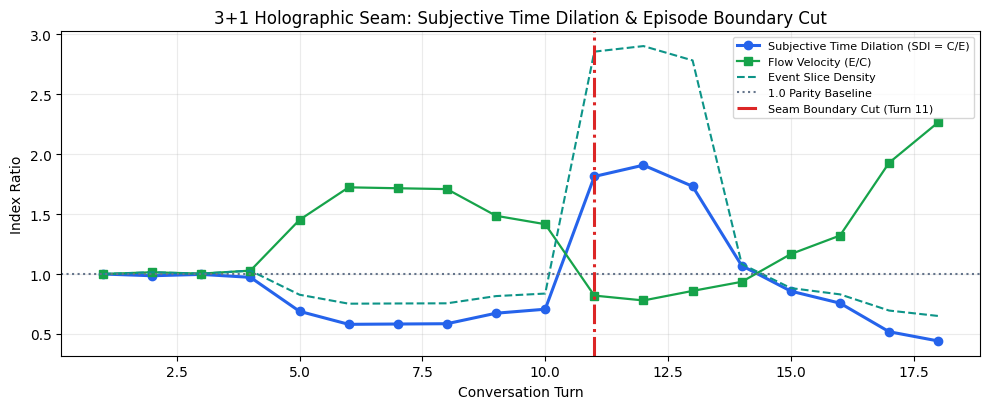

In [3]:

import numpy as np
import matplotlib.pyplot as plt
import seam_time_v2 as sts

memory_mgr = sts.SeamContextMemoryManager(profile="STANDARD", min_episode_turns=3)

conversation_log = [
    (45, 0.86, 0.35, "Init", "User", "Analyze system latency across our distributed worker nodes."),
    (46, 0.87, 0.34, "Init", "Assistant", "Initializing telemetry inspection across 16 worker nodes."),
    (45, 0.86, 0.35, "Init", "User", "Check database connection pooling first."),
    (47, 0.88, 0.33, "Init", "Assistant", "Querying PostgreSQL pool metrics and lock wait times."),
    (72, 0.94, 0.18, "Tool Flow", "Assistant", "Tool[pg_stat]: Active connections at 42/100, zero deadlocks."),
    (75, 0.95, 0.16, "Tool Flow", "Assistant", "Tool[redis_info]: Cache hit ratio steady at 98.4%."),
    (74, 0.95, 0.17, "Tool Flow", "Assistant", "Tool[net_probe]: Inter-node RTT averaging 1.2ms."),
    (76, 0.96, 0.15, "Tool Flow", "Assistant", "Tool[cpu_load]: Worker CPU utilization balanced at 34%."),
    (73, 0.94, 0.18, "Tool Flow", "Assistant", "Tool[disk_io]: NVMe write queue depth nominal at 2."),
    (75, 0.95, 0.16, "Tool Flow", "Assistant", "All infrastructure metrics confirm healthy baseline operation."),
    (28, 0.42, 0.92, "Conflict/Pivot", "User", "Wait—production alerts just spiked 400% despite those healthy metrics!"),
    (25, 0.39, 0.95, "Conflict/Pivot", "Assistant", "Contradiction detected: external ingress failing while internal nodes look idle."),
    (32, 0.55, 0.78, "Conflict/Pivot", "Assistant", "Pivoting hypothesis: checking API gateway TLS handshake & DNS routing."),
    (40, 0.74, 0.50, "Conflict/Pivot", "Assistant", "Root cause isolated: expired edge certificate dropping 80% of traffic before ingress."),
    (48, 0.86, 0.34, "Synthesis", "Assistant", "Synthesizing remediation plan for edge TLS certificate rotation."),
    (50, 0.88, 0.32, "Synthesis", "User", "Confirm zero-downtime rollout steps."),
    (74, 0.95, 0.16, "Output Glide", "Assistant", "Step 1: Deploy renewed wildcard cert to edge load balancers."),
    (76, 0.96, 0.15, "Output Glide", "Assistant", "Step 2: Verify TLS 1.3 handshake success rate returns to 99.9%."),
]

sdi_vals, vel_vals, slice_vals, cut_turns = [], [], [], []
for idx, (tps, prob, ent, phase, role, text) in enumerate(conversation_log, 1):
    res = memory_mgr.ingest_turn(idx, role, text, phase, tps, prob, ent)
    sdi_vals.append(res["sdi"])
    vel_vals.append(res["flow_velocity"])
    slice_vals.append(res["slice_density"])
    if res["cut_triggered"]:
        cut_turns.append(idx)

print(memory_mgr.build_prompt_context())

fig, ax = plt.subplots(figsize=(10, 4.2))
turns = np.arange(1, len(conversation_log) + 1)
ax.plot(turns, sdi_vals, marker="o", linewidth=2.2, color="#2563eb", label="Subjective Time Dilation (SDI = C/E)")
ax.plot(turns, vel_vals, marker="s", linewidth=1.6, color="#16a34a", label="Flow Velocity (E/C)")
ax.plot(turns, slice_vals, linestyle="--", linewidth=1.5, color="#0d9488", label="Event Slice Density")
ax.axhline(1.0, color="#64748b", linestyle=":", label="1.0 Parity Baseline")
for c in cut_turns:
    ax.axvline(c, color="#dc2626", linestyle="-.", linewidth=2.2, label=f"Seam Boundary Cut (Turn {c})")

ax.set_title("3+1 Holographic Seam: Subjective Time Dilation & Episode Boundary Cut")
ax.set_xlabel("Conversation Turn")
ax.set_ylabel("Index Ratio")
ax.legend(loc="upper right", fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [4]:

import time
import seam_time_v2 as sts

regimes = [
    (1, 10, "Discovery", 46.0, 0.87, 0.34),
    (11, 28, "Codebase Audit", 75.0, 0.95, 0.16),
    (29, 34, "Schema Conflict", 26.0, 0.40, 0.93),
    (35, 52, "Migration Execution", 78.0, 0.96, 0.15),
    (53, 57, "Latency Anomaly", 24.0, 0.38, 0.95),
    (58, 75, "Hotfix & Load Test", 74.0, 0.95, 0.17),
    (76, 80, "Security Audit Pivot", 28.0, 0.43, 0.91),
    (81, 100, "Final Verification", 77.0, 0.96, 0.15),
]

mgr = sts.SeamContextMemoryManager(profile="STANDARD", min_episode_turns=3)
total_raw_tokens, latencies_ms, boundary_turns = 0, [], []

for start, end, phase, tps, prob, ent in regimes:
    for turn in range(start, end + 1):
        role = "User" if turn % 4 == 1 else "Assistant"
        content = (
            f"[{phase} | Turn {turn:03d}] Executing distributed verification step {turn} across "
            f"cluster shards, validating transaction logs, replication lag, TLS handshakes, "
            f"and memory allocation metrics to ensure zero regression before deployment."
        )
        total_raw_tokens += max(12, len(content.split()) * 2)
        t0 = time.perf_counter()
        res = mgr.ingest_turn(turn, role, content, phase, tps, prob, ent)
        latencies_ms.append((time.perf_counter() - t0) * 1000.0)
        if res["cut_triggered"]:
            boundary_turns.append(turn)

archived_tokens = sum(max(10, len(c.summary.split()) * 2) for c in mgr.archived_episodes)
active_tokens = sum(t["tokens"] for t in mgr.active_buffer)
final_tokens = archived_tokens + active_tokens
savings_pct = (1.0 - (final_tokens / total_raw_tokens)) * 100.0

print("=== 100-TURN MARATHON BENCHMARK ===")
print(f"Mean Step Latency        : {sum(latencies_ms)/len(latencies_ms):.4f} ms / turn")
print(f"Seam Boundary Cuts       : {len(boundary_turns)} cuts at turns {boundary_turns}")
print(f"Minimum Episode Length   : {min(c.turn_count for c in mgr.archived_episodes)} turns (0 single-turn shards)")
print(f"Token Compression        : ~{total_raw_tokens:,} raw -> ~{final_tokens:,} active ({savings_pct:.1f}% reduction)")

=== 100-TURN MARATHON BENCHMARK ===
Mean Step Latency        : 0.0598 ms / turn
Seam Boundary Cuts       : 3 cuts at turns [29, 53, 76]
Minimum Episode Length   : 23 turns (0 single-turn shards)
Token Compression        : ~6,062 raw -> ~1,928 active (68.2% reduction)


In [5]:

import numpy as np
import seam_time_v2 as sts

try:
    from scipy.datasets import electrocardiogram
    ecg = electrocardiogram()
    fs = 360
    win_len = 2 * fs
    windows = [ecg[4500 + i * win_len : 4500 + (i + 1) * win_len] for i in range(24)]
    source_name = "SciPy MIT-BIH 360 Hz Human ECG"
except Exception:
    rng = np.random.default_rng(7)
    t = np.linspace(0, 2.0, 720)
    windows = [
        (np.sin(2 * np.pi * 1.2 * t) + (1.8 * np.sin(2 * np.pi * 11.5 * t) + 0.65 * rng.normal(size=720) if 10 <= i <= 13 else 0.08 * rng.normal(size=720)))
        for i in range(24)
    ]
    source_name = "Synthetic 360 Hz Sinus-to-Arrhythmia ECG"

bio_analyzer = sts.SeamTemporalAnalyzer(profile="STANDARD")
bio_cuts = []

print(f"=== BIOMETRIC EVENT SEGMENTATION ({source_name}) ===")
for idx, win in enumerate(windows, 1):
    rms = float(np.sqrt(np.mean(win ** 2))) + 1e-6
    ent = float(np.std(np.diff(win)) / rms)
    w_c = win - np.mean(win)
    lag1 = float(np.dot(w_c[:-1], w_c[1:]) / (np.dot(w_c, w_c) + 1e-9))
    coh = max(0.05, min(0.99, (lag1 + 1.0) * 0.5))

    rep = bio_analyzer.process_llm_step(tokens_per_sec=rms * 50.0, mean_token_prob=coh, token_entropy=ent)
    if rep["unified_episode_boundary"]:
        bio_cuts.append(idx)
        print(f">>> [PHYSIOLOGICAL SEAM CUT @ Window {idx:02d} ({idx*2}s)] SDI={rep['sdi']:.3f} <<<")

print(f"Detected {len(bio_cuts)} physiological regime boundary(s) at window(s): {bio_cuts}")

=== BIOMETRIC EVENT SEGMENTATION (SciPy MIT-BIH 360 Hz Human ECG) ===
>>> [PHYSIOLOGICAL SEAM CUT @ Window 21 (42s)] SDI=1.755 <<<
>>> [PHYSIOLOGICAL SEAM CUT @ Window 24 (48s)] SDI=1.737 <<<
Detected 2 physiological regime boundary(s) at window(s): [21, 24]


In [6]:

import os
import time
import seam_time_v2 as sts

try:
    from google.colab import userdata
    api_key = userdata.get("GEMINI_API_KEY")
except Exception:
    api_key = os.environ.get("GEMINI_API_KEY")

if not api_key:
    print("ℹ️ No GEMINI_API_KEY found in Colab Secrets.")
else:
    from google import genai
    client = genai.Client(api_key=api_key)
    live_mgr = sts.SeamContextMemoryManager(profile="STANDARD", min_episode_turns=3)

    prompts = [
        ("Architecture", "Briefly explain PostgreSQL connection pooling in 2 sentences."),
        ("Architecture", "What is PgBouncer transaction pooling in 2 sentences?"),
        ("Architecture", "List 2 connection timeout best practices."),
        ("Crisis Pivot", "WAIT—contradiction! Production alerts spiked 400% with TLS handshake drops while DB CPU is 5%! Diagnose immediately."),
    ]
    for i, (phase, q) in enumerate(prompts, 1):
        t0 = time.perf_counter()
        resp = client.models.generate_content(model="gemini-3.8-flash", contents=q)
        dt = max(0.1, time.perf_counter() - t0)
        ans = resp.text.strip().replace("\n", " ")[:160]
        tps = (len(ans.split()) * 1.3) / dt
        ent = 0.92 if "Crisis" in phase else 0.22
        prob = 0.42 if "Crisis" in phase else 0.92
        state = live_mgr.ingest_turn(i, "User/Gemini", f"Q: {q} -> A: {ans}", phase, tps, prob, ent)
        print(f"Turn {i:02d} [{phase}] | Mode: {state['mode']} | SDI: {state['sdi']:.3f} | Cut: {state['cut_triggered']}")

Turn 01 [Architecture] | Mode: STEADY_STATE | SDI: 1.000 | Cut: False
Turn 02 [Architecture] | Mode: STEADY_STATE | SDI: 0.934 | Cut: False
Turn 03 [Architecture] | Mode: MOMENTUM_GLIDE | SDI: 0.593 | Cut: False
Turn 04 [Crisis Pivot] | Mode: MODE_A_HARD_STABILIZE | SDI: 1.522 | Cut: True
